Contract Strike Rate: 84.68
Expected Positive Exposure (EPE): INR 2,643,839.70
SIMM Initial Margin Proxy (Day 0): INR 6,316,163.38
Max PFE (95%): INR 18,409,624.65


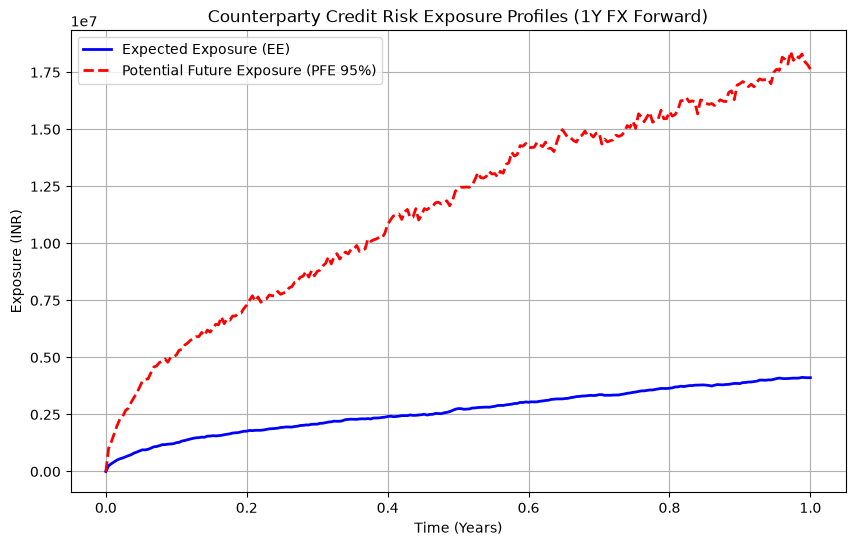

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

class MarketSimulator:
    """Simulates market paths using Geometric Brownian Motion (GBM)."""
    def __init__(self, spot, drift, vol, t_span, steps, paths):
        self.spot = spot
        self.drift = drift
        self.vol = vol
        self.t_span = t_span
        self.steps = steps
        self.paths = paths
        self.dt = t_span / steps
        self.time_grid = np.linspace(0, t_span, steps + 1)
        
    def generate_paths(self):
        """Returns a matrix of simulated asset prices (paths x time_steps)."""
        np.random.seed(42) # For reproducibility during interviews
        Z = np.random.standard_normal((self.paths, self.steps))
        # GBM exact solution
        growth_factor = np.exp((self.drift - 0.5 * self.vol**2) * self.dt + self.vol * np.sqrt(self.dt) * Z)
        
        paths = np.zeros((self.paths, self.steps + 1))
        paths[:, 0] = self.spot
        for t in range(1, self.steps + 1):
            paths[:, t] = paths[:, t-1] * growth_factor[:, t-1]
        return self.time_grid, paths

class FXForwardPricer:
    """Prices an FX Forward across simulated paths and time grids."""
    def __init__(self, notional, strike, r_dom, r_for, maturity):
        self.notional = notional
        self.strike = strike
        self.r_dom = r_dom
        self.r_for = r_for
        self.maturity = maturity
        
    def calculate_mtm(self, time_grid, spot_paths):
        """
        Calculates Mark-to-Market (MtM) value at each time step t.
        MtM = N * (S_t * exp(-r_f * (T-t)) - K * exp(-r_d * (T-t)))
        """
        paths, time_steps = spot_paths.shape
        mtm_matrix = np.zeros((paths, time_steps))
        
        for idx, t in enumerate(time_grid):
            if t > self.maturity:
                break
            time_to_maturity = self.maturity - t
            # Forward pricing formula
            asset_leg = spot_paths[:, idx] * np.exp(-self.r_for * time_to_maturity)
            cash_leg = self.strike * np.exp(-self.r_dom * time_to_maturity)
            mtm_matrix[:, idx] = self.notional * (asset_leg - cash_leg)
            
        return mtm_matrix

class ExposureCalculator:
    """Extracts EE, PFE, and computes SIMM-style Margin."""
    def __init__(self, mtm_matrix, time_grid):
        self.mtm = mtm_matrix
        self.time_grid = time_grid
        # Exposure is max(MtM, 0) - bank only has risk when the trade is an asset
        self.exposure = np.maximum(self.mtm, 0)
        
    def get_expected_exposure(self):
        return np.mean(self.exposure, axis=0)
        
    def get_pfe(self, percentile=95):
        return np.percentile(self.exposure, percentile, axis=0)
    
    def get_epe(self):
        """Expected Positive Exposure (time-averaged EE)."""
        ee = self.get_expected_exposure()
        return np.trapezoid(ee, self.time_grid) / self.time_grid[-1]
    
    def calculate_simm_im_proxy(self, spot, notional, r_for, maturity, risk_weight=0.08):
        """
        Approximates ISDA SIMM Initial Margin using Delta sensitivity.
        Delta = dV/dS = N * exp(-r_f * T)
        """
        delta_sensitivity = notional * np.exp(-r_for * maturity)
        # In SIMM, Margin = Risk_Weight * Sensitivity
        initial_margin = risk_weight * delta_sensitivity * spot
        return initial_margin

# --- Execution Block ---
if __name__ == "__main__":
    # 1. Market Parameters (e.g., USD/INR FX Rate)
    S0 = 83.00        # Spot FX rate
    r_dom = 0.07      # Domestic rate (INR)
    r_for = 0.05      # Foreign rate (USD)
    vol = 0.12        # 12% annual volatility
    drift = r_dom - r_for # Covered interest parity drift
    
    # Simulation Parameters
    T = 1.0           # 1-year maturity
    steps = 250       # Daily steps
    num_paths = 1000
    
    # Contract Parameters
    notional = 1_000_000 # 1 Million USD Notional
    strike = S0 * np.exp(drift * T) # At-the-money forward strike (approx 84.67)
    
    # 2. Run Modules
    simulator = MarketSimulator(S0, drift, vol, T, steps, num_paths)
    t_grid, spot_paths = simulator.generate_paths()
    
    pricer = FXForwardPricer(notional, strike, r_dom, r_for, T)
    mtm_paths = pricer.calculate_mtm(t_grid, spot_paths)
    
    risk_engine = ExposureCalculator(mtm_paths, t_grid)
    ee = risk_engine.get_expected_exposure()
    pfe = risk_engine.get_pfe(95)
    epe = risk_engine.get_epe()
    im_proxy = risk_engine.calculate_simm_im_proxy(S0, notional, r_for, T)
    
    # 3. Output Results
    print(f"Contract Strike Rate: {strike:.2f}")
    print(f"Expected Positive Exposure (EPE): INR {epe:,.2f}")
    print(f"SIMM Initial Margin Proxy (Day 0): INR {im_proxy:,.2f}")
    print(f"Max PFE (95%): INR {np.max(pfe):,.2f}")

    # 4. Visualization
    plt.figure(figsize=(10, 6))
    plt.plot(t_grid, ee, label='Expected Exposure (EE)', color='blue', linewidth=2)
    plt.plot(t_grid, pfe, label='Potential Future Exposure (PFE 95%)', color='red', linestyle='--', linewidth=2)
    plt.title('Counterparty Credit Risk Exposure Profiles (1Y FX Forward)')
    plt.xlabel('Time (Years)')
    plt.ylabel('Exposure (INR)')
    plt.legend()
    plt.grid(True)
    plt.show()

================ PORTFOLIO COUNTERPARTY RISK METRICS ================
Gross CVA (No Netting Agreement):  $5,764.96
Net CVA (With ISDA Master Netting): $2,570.96
Netting Capital & Reserve Benefit:   55.40% reduction
Max Gross 95% PFE:                  $605,197.08
Max Net 95% PFE:                    $508,127.69


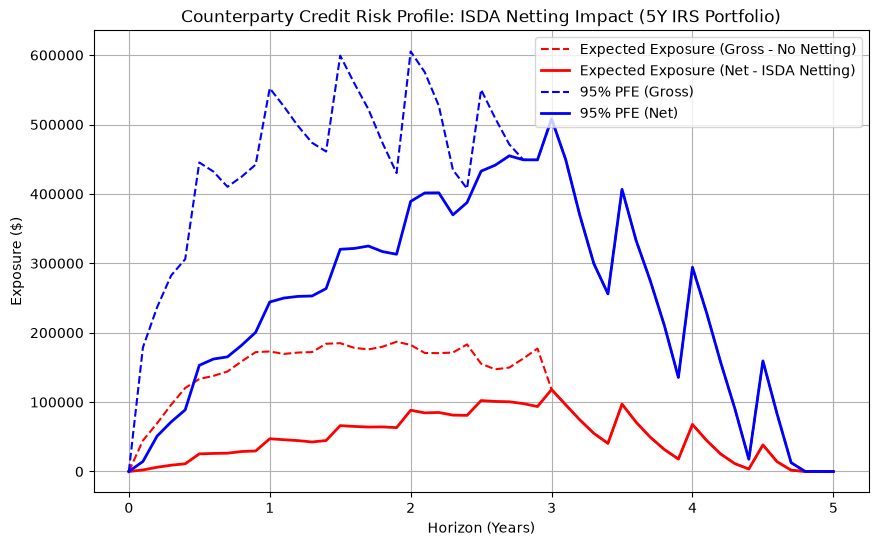

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

class HullWhite1F:
    """1-Factor Hull-White Short Rate Simulator with flat initial yield curve."""
    def __init__(self, r0=0.04, a=0.1, sigma=0.015):
        self.r0 = r0          # Initial short rate
        self.a = a            # Mean reversion speed
        self.sigma = sigma    # Volatility of short rate

    def simulate_paths(self, t_grid, num_paths=1000, seed=42):
        np.random.seed(seed)
        num_steps = len(t_grid) - 1
        r = np.zeros((num_paths, len(t_grid)))
        r[:, 0] = self.r0

        for i in range(num_steps):
            dt = t_grid[i+1] - t_grid[i]
            t = t_grid[i]
            # Drift for flat initial curve r0: theta(t) = a*r0 + (sigma^2 / (2*a))*(1 - exp(-2*a*t))
            theta_t = self.a * self.r0 + (self.sigma**2 / (2 * self.a)) * (1.0 - np.exp(-2 * self.a * t))
            
            # Exact Euler-Maruyama discretization for Ornstein-Uhlenbeck
            drift = (theta_t - self.a * r[:, i]) * dt
            diffusion = self.sigma * np.sqrt(dt) * np.random.standard_normal(num_paths)
            r[:, i+1] = r[:, i] + drift + diffusion

        return r

    def zero_coupon_bond(self, r_t, t, T):
        """Analytical ZCB price P(t, T) given short rate r_t."""
        if t >= T:
            return np.ones_like(r_t)
        dt = T - t
        B = (1.0 - np.exp(-self.a * dt)) / self.a
        # Forward curve fitting adjustment for flat yield curve r0
        A = np.exp(
            -self.r0 * dt 
            + (self.sigma**2 / (4 * self.a**3)) * (1.0 - np.exp(-2 * self.a * t)) * (1.0 - np.exp(-self.a * dt))**2
            - (self.sigma**2 / (2 * self.a**2)) * (dt - B)
        )
        return A * np.exp(-B * (r_t - self.r0))


class VanillaIRS:
    """Vanilla Fixed-for-Floating Interest Rate Swap."""
    def __init__(self, notional, fixed_rate, maturity, pay_fixed=True, payment_freq=0.5):
        self.notional = notional
        self.fixed_rate = fixed_rate
        self.maturity = maturity
        self.pay_fixed = pay_fixed
        self.freq = payment_freq
        self.fixed_schedule = np.arange(payment_freq, maturity + 1e-6, payment_freq)

    def price(self, hw_model, r_t, t):
        """MtM valuation of the swap at time t under current short rates r_t."""
        if t >= self.maturity:
            return np.zeros_like(r_t)

        remaining_dates = self.fixed_schedule[self.fixed_schedule > t]
        if len(remaining_dates) == 0:
            return np.zeros_like(r_t)

        # 1. Fixed Leg Value = Notional * FixedRate * dt * sum(P(t, T_i))
        pv_fixed_leg = np.zeros_like(r_t)
        for t_pay in remaining_dates:
            p_pay = hw_model.zero_coupon_bond(r_t, t, t_pay)
            pv_fixed_leg += self.fixed_rate * self.freq * p_pay

        # 2. Floating Leg Value = Notional * (P(t, start) - P(t, maturity))
        # Assuming next reset is at t: P(t, t) = 1.0
        p_maturity = hw_model.zero_coupon_bond(r_t, t, self.maturity)
        pv_floating_leg = 1.0 - p_maturity

        # 3. Net Swap Value
        if self.pay_fixed:
            mtm = self.notional * (pv_floating_leg - pv_fixed_leg)
        else:
            mtm = self.notional * (pv_fixed_leg - pv_floating_leg)

        return mtm


class PortfolioRiskEngine:
    """Computes Gross vs Net Exposures, PFE, and Uncollateralized CVA."""
    def __init__(self, swaps, hw_model, t_grid):
        self.swaps = swaps
        self.hw = hw_model
        self.t_grid = t_grid

    def evaluate_portfolio(self, short_rates):
        num_paths, num_steps = short_rates.shape
        num_swaps = len(self.swaps)
        
        # Cube to hold [swap_idx, path, time_step]
        trade_mtm_cube = np.zeros((num_swaps, num_paths, num_steps))

        for s_idx, swap in enumerate(self.swaps):
            for t_idx, t in enumerate(self.t_grid):
                trade_mtm_cube[s_idx, :, t_idx] = swap.price(self.hw, short_rates[:, t_idx], t)

        # 1. Without ISDA Netting: sum(max(V_i, 0))
        gross_exposure_paths = np.sum(np.maximum(trade_mtm_cube, 0), axis=0)

        # 2. With ISDA Close-Out Netting: max(sum(V_i), 0)
        net_portfolio_mtm = np.sum(trade_mtm_cube, axis=0)
        net_exposure_paths = np.maximum(net_portfolio_mtm, 0)

        return gross_exposure_paths, net_exposure_paths

    def compute_cva(self, expected_exposure, recovery_rate=0.40, flat_hazard_rate=0.02):
        """
        Uncollateralized Bilateral CVA:
        CVA = (1 - R) * sum_i [ DiscountFactor(t_i) * EE(t_i) * (PD(t_i) - PD(t_{i-1})) ]
        """
        cva = 0.0
        r0 = self.hw.r0
        
        for i in range(1, len(self.t_grid)):
            t_mid = 0.5 * (self.t_grid[i] + self.t_grid[i-1])
            dt = self.t_grid[i] - self.t_grid[i-1]
            
            # Risk-free discount factor
            df = np.exp(-r0 * t_mid)
            
            # Marginal default probability: dPD = exp(-lambda*t_{i-1}) - exp(-lambda*t_i)
            pd_prev = 1.0 - np.exp(-flat_hazard_rate * self.t_grid[i-1])
            pd_curr = 1.0 - np.exp(-flat_hazard_rate * self.t_grid[i])
            marginal_pd = pd_curr - pd_prev
            
            # Midpoint Expected Exposure
            mid_ee = 0.5 * (expected_exposure[i] + expected_exposure[i-1])
            cva += (1.0 - recovery_rate) * df * mid_ee * marginal_pd

        return cva


if __name__ == "__main__":
    # Simulation Horizon: 5 Years, 50 Steps
    t_grid = np.linspace(0, 5, 51)
    num_paths = 1000

    hw = HullWhite1F(r0=0.04, a=0.1, sigma=0.012)
    rates = hw.simulate_paths(t_grid, num_paths=num_paths)

    # Netting Set with 2 Swaps (Payer and Receiver)
    # Swap 1: Pay-Fixed 5Y 4.2% Notional $10M
    swap1 = VanillaIRS(notional=10_000_000, fixed_rate=0.042, maturity=5.0, pay_fixed=True)
    # Swap 2: Receive-Fixed 3Y 3.8% Notional $8M (Offsetting position)
    swap2 = VanillaIRS(notional=8_000_000, fixed_rate=0.038, maturity=3.0, pay_fixed=False)

    portfolio = [swap1, swap2]
    engine = PortfolioRiskEngine(portfolio, hw, t_grid)

    gross_exp, net_exp = engine.evaluate_portfolio(rates)

    # Metrics
    ee_gross = np.mean(gross_exp, axis=0)
    ee_net = np.mean(net_exp, axis=0)
    pfe_95_gross = np.percentile(gross_exp, 95, axis=0)
    pfe_95_net = np.percentile(net_exp, 95, axis=0)

    # Calculate CVA
    cva_gross = engine.compute_cva(ee_gross, recovery_rate=0.40, flat_hazard_rate=0.02)
    cva_net = engine.compute_cva(ee_net, recovery_rate=0.40, flat_hazard_rate=0.02)
    netting_benefit = (1.0 - (cva_net / cva_gross)) * 100

    print("================ PORTFOLIO COUNTERPARTY RISK METRICS ================")
    print(f"Gross CVA (No Netting Agreement):  ${cva_gross:,.2f}")
    print(f"Net CVA (With ISDA Master Netting): ${cva_net:,.2f}")
    print(f"Netting Capital & Reserve Benefit:   {netting_benefit:.2f}% reduction")
    print(f"Max Gross 95% PFE:                  ${np.max(pfe_95_gross):,.2f}")
    print(f"Max Net 95% PFE:                    ${np.max(pfe_95_net):,.2f}")

    # Plot Exposure Profiles
    plt.figure(figsize=(10, 6))
    plt.plot(t_grid, ee_gross, 'r--', label='Expected Exposure (Gross - No Netting)')
    plt.plot(t_grid, ee_net, 'r-', linewidth=2, label='Expected Exposure (Net - ISDA Netting)')
    plt.plot(t_grid, pfe_95_gross, 'b--', label='95% PFE (Gross)')
    plt.plot(t_grid, pfe_95_net, 'b-', linewidth=2, label='95% PFE (Net)')
    plt.title('Counterparty Credit Risk Profile: ISDA Netting Impact (5Y IRS Portfolio)')
    plt.xlabel('Horizon (Years)')
    plt.ylabel('Exposure ($)')
    plt.grid(True)
    plt.legend()
    plt.show()